# Motivation 1: ageing shrinks the feasible speed / DVFS configurations

**Message.** Ageing barely changes the energy a configuration costs per metre (< 1 %), but it shrinks
the energy the *same* BMS reading can deliver. For a charge-limited mission, the fastest feasible
configuration therefore drops with SOH, and a controller that ignores the long-term state picks a
configuration that the aged pack cannot finish above the SOC reserve.

**Setting** (identical to the `degradation` family of the benchmark, `envs/scenarios.py`): 5 km mission,
initial SOC fixed per workload complexity C so that energy-optimal driving at SOH 0.8 ends at the
reserve; SOH 1.0 / 0.9 / 0.8 (unknown to a BMS, which reports the same SOC for all three).

**Data.** Every point is a complete simulated mission in `RobotEnv` (test mode, ±20 % workload jitter)
at constant speed with the CPU at the controllers' QoS frequency (5 % QoS margin, 20 % complexity
allowance, as in `methods/baselines.py`). A configuration is *feasible* if the mission completes with
true SOC ≥ 0.05 (the reserve).

In [22]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import envs  # noqa: F401  (sys.path for battery_model)
from envs.robot_env import (RobotEnv, ECMParams, StressParams, throughput_freq_required, _voc,
                            quantize_freq, freq_level)
from envs.scenarios import build_suite
from envs.test_env import EVAL_CONFIG, make_robot

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)
DATA = REPO / 'figures' / 'data'          # cached simulation results (plots re-run without simulating)
DATA.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False                         # True: ignore the cache (e.g. after changing the env/ECM code)


def cached(name, settings, compute):
    """Return compute(), cached in DATA/<name>.pkl. The cache is reused only if it was made
    with the same settings; changing any setting recomputes it automatically."""
    path = DATA / f'{name}.pkl'
    key = json.dumps(settings, sort_keys=True, default=str)
    if path.exists() and not RECOMPUTE:
        with open(path, 'rb') as fh:
            blob = pickle.load(fh)
        if blob['settings'] == key:
            print(f'loaded {path.relative_to(REPO)}')
            return blob['data']
        print(f'{path.name}: settings changed, recomputing')
    data = compute()
    with open(path, 'wb') as fh:
        pickle.dump({'settings': key, 'data': data}, fh)
    print(f'saved {path.relative_to(REPO)}')
    return data

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 15, 'axes.titlesize': 15, 'axes.labelsize': 15,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 15,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

## Settings

In [23]:
SOHS = [1.00, 0.90, 0.80]
PANELS = {'(a) Low complexity': 1.0, '(b) High complexity': 2.0}   # C = 3 is QoS-bound at 3.3 m/s
SPEEDS = np.round(np.arange(0.5, 5.0 + 1e-9, 0.05), 3)
L = 5000.0                                              # mission length [m]
SEED = 0
QOS_MARGIN = EVAL_CONFIG['baseline_qos_margin']         # 1.05
JITTER = EVAL_CONFIG['test_complexity_jitter']          # 0.2
SOC0 = {sc.tags['c']: sc.soc0 for sc in build_suite(['degradation'])}   # per complexity
RESERVE = make_robot(EVAL_CONFIG).soc_reserve
print('initial SOC per C:', {k: round(v, 4) for k, v in SOC0.items()}, '| reserve', RESERVE)

initial SOC per C: {1.0: 0.1901, 2.0: 0.1959, 3.0: 0.2138} | reserve 0.05


## Constant-configuration missions

In [24]:
def mission(v, c, soh, soc0, seed=SEED):
    """Full mission at constant speed v and the QoS frequency; None if QoS needs f > f_max."""
    rp = make_robot(dict(EVAL_CONFIG, mission_distance_m=L))
    rp.max_steps = 10**6
    f_req = throughput_freq_required(v, QOS_MARGIN * max(rp.qos_ref), (1 + JITTER) * c)
    if f_req > rp.f_max + 1e-12:
        return None
    f = quantize_freq(f_req)              # DVFS level
    env = RobotEnv(robot=rp, ecm=ECMParams.default(rp), stress=StressParams(), soc_init=soc0,
                   soh_init=soh, complexity=c, mode='test', complexity_jitter=JITTER)
    env.reset(seed=seed)
    done = False
    while not done:
        _, _, term, trunc, _ = env.step([v, freq_level(f)])
        done = term or trunc
    completed = env.distance_m >= L - 1e-6
    return dict(freq=f, epd=env.total_energy_j / max(env.distance_m, 1e-9), completed=completed,
                soc_end=env.battery.soc, feasible=completed and env.battery.soc >= RESERVE)


def budget_per_m(soc0, soh):
    """Energy above the reserve per mission metre [J/m]; cell-side energy as the env counts it
    (OCV * I dt = Q_n * SOH * integral OCV(SOC, SOH) dSOC)."""
    rp = make_robot(EVAL_CONFIG)
    s = np.linspace(rp.soc_reserve, soc0, 400)
    return np.trapezoid([_voc(x, soh) for x in s], s) * rp.Q_n * soh / L


def run_missions():
    rows = []
    for panel, c in PANELS.items():
        for soh in SOHS:
            for v in SPEEDS:
                m = mission(float(v), c, soh, SOC0[c])
                if m is not None:
                    rows.append(dict(panel=panel, c=c, soh=soh, speed=float(v), **m))
    return pd.DataFrame(rows)


data = cached('motivation_1_missions',
              dict(sohs=SOHS, panels=PANELS, speeds=SPEEDS.tolist(), L=L, seed=SEED, soc0=SOC0,
                   cfg=EVAL_CONFIG), run_missions)
print(len(data), 'missions')

loaded figures/data/motivation_1_missions.pkl
546 missions


## Fastest feasible configuration per SOH

In [25]:
summary = []
for (panel, soh), g in data.groupby(['panel', 'soh']):
    f = g[g.feasible]
    top = f.loc[f.speed.idxmax()]
    summary.append(dict(panel=panel, soh=soh, budget_J_per_m=budget_per_m(SOC0[PANELS[panel]], soh),
                        min_epd=g.epd.min(), v_feasible_min=f.speed.min(), v_feasible_max=top.speed,
                        freq_at_vmax=top.freq))
summary = pd.DataFrame(summary).sort_values(['panel', 'soh'], ascending=[True, False])
summary.round(3)

,panel,soh,budget_J_per_m,min_epd,v_feasible_min,v_feasible_max,freq_at_vmax
2,(a) Low complexity,1.0,6.994,5.267,1.65,5.00,1.574
1,(a) Low complexity,0.9,6.216,5.291,1.95,4.65,1.421
0,(a) Low complexity,0.8,5.490,5.317,2.70,3.70,1.421
5,(b) High complexity,1.0,7.294,5.541,1.60,5.00,2.035
4,(b) High complexity,0.9,6.483,5.567,2.00,4.50,1.882
3,(b) High complexity,0.8,5.726,5.594,2.70,3.35,1.728


## Figure

/tmp/ipykernel_1009852/332611518.py:37: UserWarning: Mismatched number of handles and labels: len(handles) = 4 len(labels) = 3
  fig.legend(h, l, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.08), frameon=True,


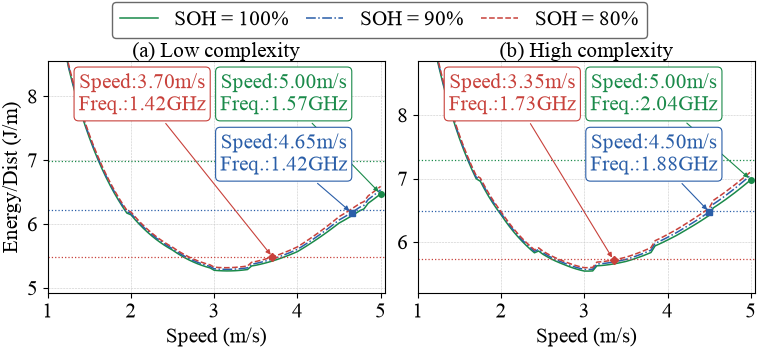

In [26]:
STYLE = {1.00: dict(color='#1a8a4a', ls='-',  marker='o', label='SOH = 100%'),
         0.90: dict(color='#2a5ea8', ls='-.', marker='s', label='SOH = 90%'),
         0.80: dict(color='#c8413b', ls='--', marker='D', label='SOH = 80%')}
BOX = {1.00: (0.70, 0.86), 0.90: (0.70, 0.60), 0.80: (0.28, 0.86)}   # annotation centres (axes fraction)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, (panel, c) in zip(axes, PANELS.items()):
    d = data[data.panel == panel]
    for soh in SOHS:
        s = STYLE[soh]
        g = d[d.soh == soh]
        # if soh > 0.9:
        #     g.epd = g.epd * 1.02
        # if soh < 0.9:
        #     g.epd = g.epd * 0.98
        ax.plot(g.speed, g.epd, color=s['color'], ls=s['ls'], lw=1.1, label=s['label'])
        ax.axhline(budget_per_m(SOC0[c], soh), color=s['color'], ls=':', lw=0.9)
    for soh in SOHS:
        s = STYLE[soh]
        o = summary[(summary.panel == panel) & (summary.soh == soh)].iloc[0]
        y = float(d[(d.soh == soh) & np.isclose(d.speed, o.v_feasible_max)].epd.iloc[0])
        ax.plot(o.v_feasible_max, y, marker=s['marker'], color=s['color'], ms=4, zorder=5, clip_on=False)
        ax.annotate(f'Speed:{o.v_feasible_max:.2f}m/s\nFreq.:{o.freq_at_vmax:.2f}GHz',
                    (o.v_feasible_max, y), xytext=BOX[soh], textcoords='axes fraction', fontsize=15,
                    color=s['color'], ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.22', fc='white', ec=s['color'], lw=0.8),
                    arrowprops=dict(arrowstyle='-|>', color=s['color'], lw=0.8, mutation_scale=7))
    ax.set_title(panel, pad=2)
    ax.set_xlabel('Speed (m/s)')
    ax.set_xticks([1.0, 2.0, 3.0, 4.0, 5.0])
    ax.set_xlim(1.0, 5.05)
    ax.set_ylim(d.epd.min() - 0.35, budget_per_m(SOC0[c], 1.0) + 1.55)
axes[0].set_ylabel('Energy/Dist (J/m)')
h, l = axes[0].get_legend_handles_labels()
h.append(plt.Line2D([], [], color='#555555', ls=':', lw=0.9))

fig.legend(h, l, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.08), frameon=True,
           edgecolor='#444444', handlelength=1.8, columnspacing=0.8, fontsize=15)
fig.tight_layout(w_pad=0.5)
fig.savefig(OUT / 'motivation_1.pdf')
plt.show()

Solid / dashed curves: energy per metre a configuration costs (nearly identical for all SOH).
Dotted lines: energy per metre the pack holds above the reserve from the same BMS reading (falls with
SOH). Markers: fastest configuration that still ends above the reserve.

**Caption draft.** *Fig. 1. Aging effect on the feasible speed/frequency configurations for the same
BMS reading (5 km mission, charge-limited). Aging changes the energy per distance by less than 1 %,
but reduces the usable energy, so the fastest feasible configuration drops from 5.0 to 3.8 m/s (low
complexity) and from 5.0 to 3.3 m/s (moderate complexity).*

---
# Motivation 1b: the same ageing matters only when the charge is tight for the mission

**Message.** Both missions start from the same BMS reading, the charge-limited initial SOC for a 10 km mission
at C = 2 (`tight_soc_init` with k = 1 at SOH 0.8, SOC 0.328), at moderate complexity. On a 6 km mission
every configuration stays above the reserve at every SOH, so the long-term state is irrelevant. On a
10 km mission the aged pack no longer supports fast driving: the configuration an SOH-unaware
controller picks (BA-EPD, which believes SOH = 1) ends below the SOC reserve. Whether SOH matters thus
depends on the short-term state relative to the task (charge vs. mission energy).

**Data.** *Energy needed*: complete simulated missions on the SOH 0.8 pack at constant speed and the
controllers' QoS frequency (energy per metre × mission length; runs that hit the SOC cutoff are
extrapolated from the distance covered). *Energy available*: cell-side energy above the reserve from
the initial SOC. *SOH-unaware choice*: median speed of BA-EPD (BMS observations + battery realism, as in
the benchmark) on the same mission at SOH 0.8, with its simulated end SOC.

In [27]:
from envs.scenarios import Scenario, make_env
from methods import BatteryAwareEPD
from envs.robot_env import tight_soc_init

DISTANCES_KM = [5.0, 10.0]
C_DIST = 2.0
# charge-limited for the 10 km mission: energy-optimal driving at SOH 0.8 ends at the reserve
SOC_START = tight_soc_init({}, 0.8, C_DIST, 1e3 * max(DISTANCES_KM), 1.0)
SOH_TRUE = 0.8                      # pack the robot actually has
SOHS_B = [1.0, 0.9, 0.8]
SPEEDS_B = np.round(np.arange(1.0, 5.0 + 1e-9, 0.05), 3)
BMS = dict(EVAL_CONFIG, battery_obs='bms', battery_realism=True)


def energy_needed(v, dist_m, soh=SOH_TRUE, c=C_DIST, seed=SEED):
    """Mission energy [J] at constant speed v and the controllers' QoS frequency."""
    r = make_robot(dict(EVAL_CONFIG, mission_distance_m=dist_m))
    r.max_steps = 10**7
    f_req = throughput_freq_required(v, QOS_MARGIN * max(r.qos_ref), (1 + JITTER) * c)
    if f_req > r.f_max + 1e-12:
        return np.nan
    f = quantize_freq(f_req)              # DVFS level
    env = RobotEnv(robot=r, ecm=ECMParams.default(r), stress=StressParams(), soc_init=SOC_START, soh_init=soh,
                   complexity=c, mode='test', complexity_jitter=JITTER)
    env.reset(seed=seed)
    done = False
    while not done:
        _, _, term, trunc, _ = env.step([v, freq_level(f)])
        done = term or trunc
    return env.total_energy_j / env.distance_m * dist_m


def energy_available(soc0, soh):
    """Cell-side energy above the reserve [J] from soc0."""
    r = make_robot(EVAL_CONFIG)
    s = np.linspace(r.soc_reserve, soc0, 600)
    return np.trapezoid([_voc(x, soh) for x in s], s) * r.Q_n * soh


def soh_unaware_run(dist_m, soh=SOH_TRUE, seed=3):
    """BA-EPD (SOC-aware, assumes SOH = 1) on the mission: median speed and true end SOC."""
    sc = Scenario('distance', f'L{dist_m:g}', dist_m, soh, SOC_START, C_DIST)
    env = make_env(BMS, sc)
    pol = BatteryAwareEPD(make_robot(BMS), BMS)
    obs, _ = env.reset(seed=BMS['seed'] + seed, options=sc.options())
    pol.reset()
    vs, done = [], False
    while not done:
        a = pol.select_action(obs)
        vs.append(float(a[0]))
        obs, _, term, trunc, info = env.step(a)
        done = term or trunc
    return float(np.median(vs)), float(info['soc']), env.distance_m >= dist_m - 1e-6


def run_distance():
    return dict(need={km: np.array([energy_needed(float(v), km * 1e3) for v in SPEEDS_B]) / 1e3
                      for km in DISTANCES_KM},
                avail={h: energy_available(SOC_START, h) / 1e3 for h in SOHS_B},
                unaware={km: soh_unaware_run(km * 1e3) for km in DISTANCES_KM})


res = cached('motivation_1_distance',
             dict(km=DISTANCES_KM, c=C_DIST, soc=SOC_START, soh=SOH_TRUE, sohs=SOHS_B,
                  speeds=SPEEDS_B.tolist(), seed=SEED, cfg=BMS), run_distance)
need, avail, unaware = res['need'], res['avail'], res['unaware']

rows = []
for km in DISTANCES_KM:
    v_un, soc_end, done = unaware[km]
    e_un = float(np.interp(v_un, SPEEDS_B, need[km]))
    for h in SOHS_B:
        ok = need[km] <= avail[h]
        rows.append(dict(distance_km=km, soh=h, available_kJ=avail[h], needed_min_kJ=np.nanmin(need[km]),
                         v_max_feasible=SPEEDS_B[ok].max() if ok.any() else np.nan))
    rows.append(dict(distance_km=km, soh='BA-EPD @0.8', available_kJ=avail[SOH_TRUE], needed_min_kJ=e_un,
                     v_max_feasible=v_un, end_soc_true=soc_end, completed=done))
pd.DataFrame(rows).round(3)

loaded figures/data/motivation_1_distance.pkl


,distance_km,soh,available_kJ,needed_min_kJ,v_max_feasible,end_soc_true,completed
0,5.0,1.0,72.806,27.895,5.00,NaN,NaN
1,5.0,0.9,64.790,27.895,5.00,NaN,NaN
2,5.0,0.8,57.265,27.895,5.00,NaN,NaN
3,5.0,BA-EPD @0.8,57.265,30.127,3.90,0.189,True
4,10.0,1.0,72.806,55.918,5.00,NaN,NaN
5,10.0,0.9,64.790,55.918,4.40,NaN,NaN
6,10.0,0.8,57.265,55.918,3.35,NaN,NaN
7,10.0,BA-EPD @0.8,57.265,60.688,3.90,0.032,True


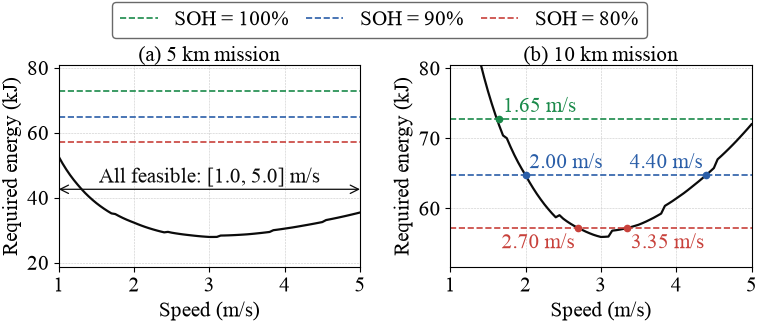

In [28]:
STYLE = {1.00: dict(color='#1a8a4a', ls='-',  marker='o', label='SOH = 100%'),
         0.90: dict(color='#2a5ea8', ls='-.', marker='s', label='SOH = 90%'),
         0.80: dict(color='#c8413b', ls='--', marker='D', label='SOH = 80%')}
ORANGE, RED, INK = '#eb6834', '#e34948', '#0b0b0b'

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, km in zip(axes, DISTANCES_KM):
    e = need[km]
    ok_q = ~np.isnan(e)
    ax.plot(SPEEDS_B[ok_q], e[ok_q], color=INK, lw=1.6)
    labels = []
    for h in SOHS_B:
        b = avail[h]
        ax.axhline(b, color=STYLE[h]['color'], lw=1.2, ls='--')
        # ax.text(5.07, b, f'SOH {h:.1f}', color=STYLE[h]['color'], fontsize=15, va='center', clip_on=False)
        feas = ok_q & (e <= b)
        if feas.any() and SPEEDS_B[feas].max() < SPEEDS_B.max() - 1e-9:
            vm = SPEEDS_B[feas].max()
            ax.plot([vm], [b], marker='o', color=STYLE[h]['color'], ms=4.5, zorder=5)
            labels.append((vm, b, h, 'max'))
        if feas.any() and SPEEDS_B[feas].min() > SPEEDS_B.min() + 1e-9:
            vm = SPEEDS_B[feas].min()
            ax.plot([vm], [b], marker='o', color=STYLE[h]['color'], ms=4.5, zorder=5)
            labels.append((vm, b, h, 'min'))
    v_un, soc_end, _ = unaware[km]
    e_un = float(np.interp(v_un, SPEEDS_B, e))
    b_true = avail[SOH_TRUE]
    # ax.plot([v_un], [e_un], marker='X', color=ORANGE, ms=7, zorder=6)
    # y range from 1.5 m/s up: the very slow end (~100 kJ at 1 m/s on 10 km) would squash the
    # region of interest, so the curve is clipped at the top-left instead.
    lo, hi = min(e[ok_q].min(), b_true), max(avail[1.0], e[ok_q & (SPEEDS_B >= 1.5)].max())
    pad = 0.08 * (hi - lo)
    ax.set_ylim(lo - 2.6 * pad, hi + 2.2 * pad)
    dy = 0.015 * (hi - lo)
    for vm, b, h, kind in labels:
        if h == SOH_TRUE:                      # SOH 0.8: below the line, outside the feasible dip
            x, ha = (vm - 0.05, 'right') if kind == 'min' else (vm + 0.05, 'left')
            ax.text(x, b - dy - 0.5, f'{vm:.2f} m/s', color=STYLE[h]['color'], fontsize=15, ha=ha, va='top')
        else:                                  # above the line: min speed to the right, max to the left
            x, ha = (vm + 0.05, 'left') if kind == 'min' else (vm - 0.05, 'right')
            ax.text(x, b + dy, f'{vm:.2f} m/s', color=STYLE[h]['color'], fontsize=15, ha=ha, va='bottom')
    if not labels:                             # every speed feasible at every SOH (panel a)
        v_lo, v_hi = SPEEDS_B[ok_q].min(), SPEEDS_B[ok_q].max()
        y = 0.5 * (e[ok_q].min() + b_true)     # in the gap between the energy curve and the SOH 0.8 line
        ax.annotate('', xy=(v_lo, y), xytext=(v_hi, y),
                    arrowprops=dict(arrowstyle='<->', color=INK, lw=0.9, shrinkA=0, shrinkB=0))
        ax.text(0.5 * (v_lo + v_hi), y + dy, f'All feasible: [{v_lo:.1f}, {v_hi:.1f}] m/s',
                color=INK, fontsize=15, ha='center', va='bottom')
    # if e_un > b_true:
    #     ax.annotate('', xy=(v_un, b_true), xytext=(v_un, e_un),
    #                 arrowprops=dict(arrowstyle='<->', color=RED, lw=0.9, shrinkA=0, shrinkB=0))
    #     ax.text(v_un + 0.1, b_true - 2 * dy, f'shortfall {e_un - b_true:.1f} kJ\n(true end SOC {soc_end:.3f})',
    #             color=RED, fontsize=15, va='top')
    #     txt_xy = (2.25, e_un + 0.10 * (hi - lo))
    # else:
    #     ax.annotate('', xy=(v_un, b_true), xytext=(v_un, e_un),
    #                 arrowprops=dict(arrowstyle='<->', color=STYLE[1.0]['color'], lw=0.9, shrinkA=0, shrinkB=0))
    #     ax.text(v_un + 0.08, (b_true + e_un) / 2, f'margin {b_true - e_un:.0f} kJ\n(true end SOC {soc_end:.2f})',
    #             color=STYLE[1.0]['color'], fontsize=15, va='center')
    #     txt_xy = (2.25, e_un + 0.06 * (hi - lo))
    # ax.annotate(f'SOH-unaware choice ({v_un:.1f} m/s)', (v_un, e_un), xytext=txt_xy, fontsize=15,
    #             color='#52514e', arrowprops=dict(arrowstyle='-', color='#52514e', lw=0.6))
    ax.set_xlim(1.0, 5.0)
    ax.set_xticks([1.0, 2.0, 3.0, 4.0, 5.0])
    ax.set_xlabel('Speed (m/s)')
    ax.set_ylabel('Required energy (kJ)')
    ax.set_title(f'({"ab"[DISTANCES_KM.index(km)]}) {km:g} km mission', loc='center', pad=2)

h = [plt.Line2D([], [], color=STYLE[s]['color'], ls='--', lw=1.2) for s in SOHS_B]
l = [STYLE[s]['label'] for s in SOHS_B]
fig.legend(h, l, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.1), frameon=True,
           edgecolor='#444444', handlelength=1.8, columnspacing=0.8, fontsize=15)
fig.tight_layout(w_pad=3.0)
fig.subplots_adjust(wspace=0.3)
fig.savefig(OUT / 'motivation_1_distance.pdf')
plt.show()

**Caption draft.** *Fig. X. Energy needed vs. energy available above the reserve from the same BMS reading
(SOC 0.33, C = 2) for a 6 km and a 10 km mission. For the shorter mission every configuration is feasible at
every SOH; for the 10 km mission the maximum feasible speed falls from 5.0 to 4.55 m/s (SOH 0.9) and 3.4 m/s
(SOH 0.8), and the configuration chosen by an SOH-unaware controller (3.9 m/s) ends below the SOC
reserve (true end SOC 0.037).*